# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

          liczba  procent
Cabin        687    77.10
Age          177    19.87
Embarked       2     0.22


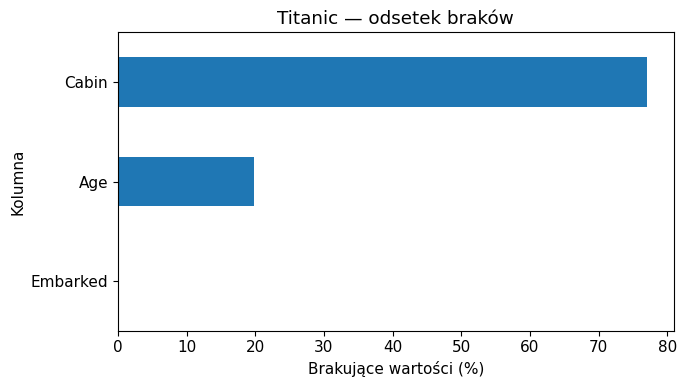

In [2]:
braki_titanic = pd.DataFrame({"liczba": titanic.isna().sum(),
                              "procent": 100 * titanic.isna().mean()})
braki_titanic = braki_titanic[braki_titanic["liczba"] > 0].sort_values("procent", ascending=False)
print(braki_titanic.round(2))
braki_titanic["procent"].sort_values().plot.barh()
plt.xlabel("Brakujące wartości (%)")
plt.ylabel("Kolumna")
plt.title("Titanic — odsetek braków")
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

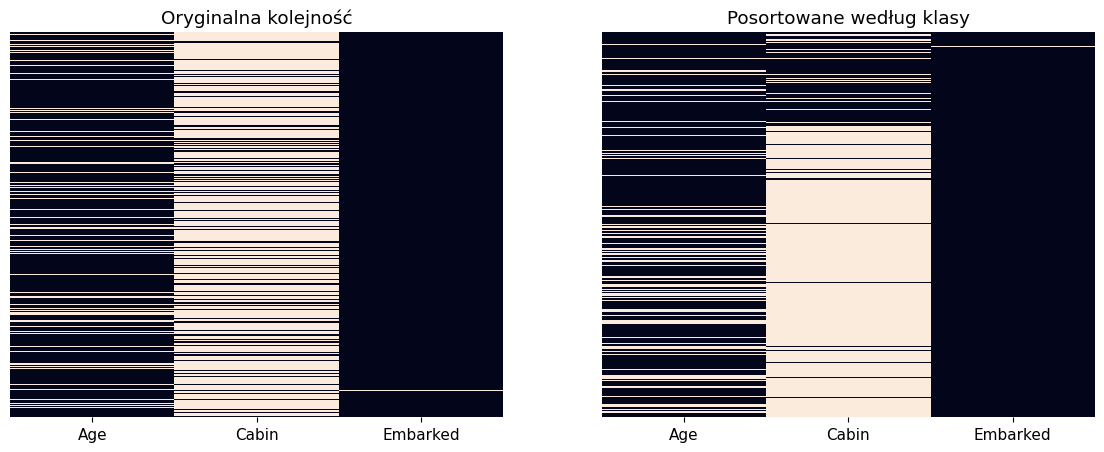

In [7]:
kolumny = ["Age", "Cabin", "Embarked"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=ax[0], yticklabels=False)
sns.heatmap(titanic.sort_values("Pclass")[kolumny].isna(), cbar=False, ax=ax[1], yticklabels=False)
ax[0].set_title("Oryginalna kolejność")
ax[1].set_title("Posortowane według klasy")
plt.tight_layout
plt.show()

*Twoja odpowiedź:* Po posortowaniu pasażerów łatwiej dostrzec, że braki w Cabin są powiązane z klasą biletu. W orginalnej kolejności jest to bardzo mało widoczny wzorzec.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Braki wieku według klasy (%):
Pclass
1    13.89
2     5.98
3    27.70
Name: Age, dtype: float64
Braki wieku według płci (%):
Sex
female    16.88
male      21.49
Name: Age, dtype: float64
Odsetek ocalałych (%):
Age
False    40.62
True     29.38
Name: Survived, dtype: float64


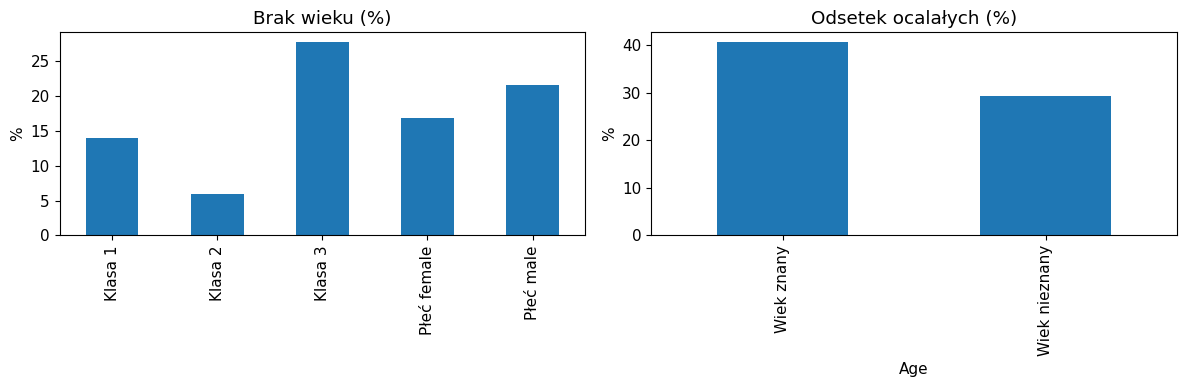

In [ ]:
brak_wieku = titanic["Age"].isna()
klasa = (100 * titanic.groupby("Pclass")["Age"].apply(lambda s: s.isna().mean()))
plec = (100 * titanic.groupby("Sex")["Age"].apply(lambda s: s.isna().mean()))
przezycie = 100 * titanic.groupby(brak_wieku)["Survived"].mean()
print("Braki wieku według klasy (%):", klasa.round(2), sep="\n")
print("Braki wieku według płci (%):", plec.round(2), sep="\n")
print("Odsetek ocalałych (%):", przezycie.round(2), sep="\n")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
klasa.plot.bar(ax=ax[0], title="Brak wieku według klasy (%)")
plec.plot.bar(ax=ax[0], color="gray", alpha=.5) if False else None
ax[0].clear()
pd.concat([klasa.rename(index=lambda x: f"Klasa {x}"),
           plec.rename(index=lambda x: f"Płeć {x}")]).plot.bar(ax=ax[0])
ax[0].set(title="Brak wieku (%)", ylabel="%")
przezycie.rename(index={False:"Wiek znany",True:"Wiek nieznany"}).plot.bar(ax=ax[1])
ax[1].set(title="Odsetek ocalałych (%)", ylabel="%")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Braki wieku różnią się pomiędzy grupami, co podważa założenie MCAR. Usunięcie rekordów bez wieku zmienia strukturę próby i może zmienić oszacowany odsetek ocalałych.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [5]:
warianty = {"bez zmian": titanic,
            "bez braków Embarked": titanic.dropna(subset=["Embarked"]),
            "bez braków Age": titanic.dropna(subset=["Age"]),
            "bez jakichkolwiek braków": titanic.dropna()}
tabela_usuwanie = pd.DataFrame({
    nazwa: {"liczba_wierszy": len(dane),
            "ocalali_%": 100*dane["Survived"].mean(),
            "klasa_1_%": 100*dane["Pclass"].eq(1).mean()}
    for nazwa, dane in warianty.items()
}).T
print(tabela_usuwanie.round(2))

                          liczba_wierszy  ocalali_%  klasa_1_%
bez zmian                          891.0      38.38      24.24
bez braków Embarked                889.0      38.25      24.07
bez braków Age                     714.0      40.62      26.05
bez jakichkolwiek braków           183.0      67.21      86.34


*Twoja odpowiedź:* dropna() - usuwa również rekordy z brakującym numerem kabiny, przez co drastycznie zmniejsza próbę i zmienia proporcję klas oraz odsetek ocalałych. Jest to najbardziej zniekształcający wariant.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

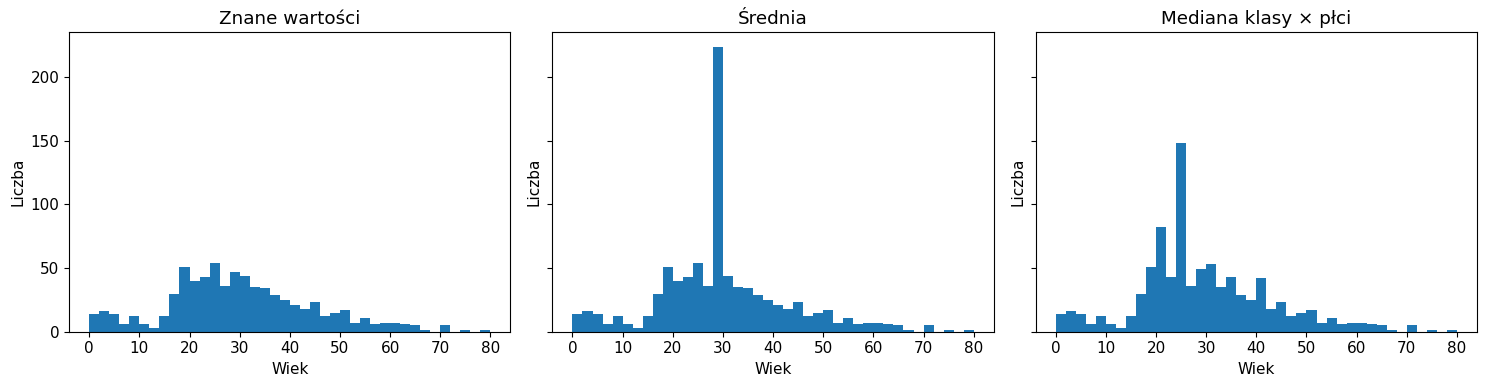

Age             14.53
wiek_srednia    13.00
wiek_grupy      13.30
dtype: float64


In [6]:
titanic["Age_brak"] = titanic["Age"].isna().astype(int)
titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
mediany_grup = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediany_grup).fillna(titanic["Age"].median())
bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (kol, tytul) in zip(axes, [("Age", "Znane wartości"),
                                   ("wiek_srednia", "Średnia"),
                                   ("wiek_grupy", "Mediana klasy × płci")]):
    ax.hist(titanic[kol].dropna(), bins=bins)
    ax.set(title=tytul, xlabel="Wiek", ylabel="Liczba")
plt.tight_layout()
plt.show()
print(titanic[["Age", "wiek_srednia", "wiek_grupy"]].std().round(2))

*Twoja odpowiedź:* Uzupełnianie średnią tworzy sztuczny pik przy jednej wartości i zwykle najbardziej obniża odchylenie standardowe. Mediany w grupach uwzględniają różnice między klasami i płciami, choć również wprowadzają sztuczne punkty.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

In [ ]:
# TODO

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [8]:
mieszkania = pd.read_csv("nieruchomosci.csv")
print(mieszkania.dtypes)
print("Braki widziane domyślnie:", mieszkania.isna().sum(), sep="\n")
print("Łącznie:", mieszkania.isna().sum().sum())

id               int64
miasto             str
dzielnica          str
powierzchnia       str
liczba_pokoi     int64
rok_budowy         str
pietro             str
liczba_pieter    int64
parking            str
balkon             str
stan               str
cena_m2          int64
cena_total       int64
dtype: object
Braki widziane domyślnie:
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64
Łącznie: 8


*Twoja odpowiedź:* Domyślnie pandas wykrywa 8 braków: 4 w powierzchnia i 4 w rok_budowy. Kolumna powierzchnia ma typ object, ponieważ zawiera również tekst brak

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [9]:
surowe = pd.read_csv("nieruchomosci.csv")
for kol in surowe.columns:
    print(f"\n{kol}:")
    print(surowe[kol].value_counts(dropna=False).to_string())


id:
id
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    1
16    1
17    1
18    1
19    1
20    1
21    1
22    1
23    1
24    1
25    1
26    1
27    1
28    1
29    1
30    1
31    1
32    1
33    1
34    1
35    1
36    1
37    1
38    1
39    1
40    1
41    1
42    1
43    1
44    1
45    1

miasto:
miasto
Warszawa    9
Kraków      9
Wrocław     9
Poznań      9
Gdańsk      9

dzielnica:
dzielnica
Krzyki           2
Grunwald         2
Śródmieście      2
Stare Miasto     2
Mokotów          1
Krowodrza        1
Wrzeszcz         1
Podgórze         1
Jeżyce           1
Oliwa            1
Żoliborz         1
Kazimierz        1
Psie Pole        1
Rataje           1
Siedlce          1
Praga            1
Nowa Huta        1
Fabryczna        1
Wilda            1
Przymorze        1
Ochota           1
Bronowice        1
Centrum          1
Ursynów          1
Dębniki          1
Zaspa            1
Wilanów          1
Łagiewniki 

*Twoja odpowiedź:* Ukryte braki: powierzchnia — brak, 0; rok_budowy — brak; pietro — brak, -999; parking i balkon — ?; cena_m2 — -1, -999. Zwykłe puste pola są rozpoznawane automatycznie.

In [10]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": [-1, -999],
}
mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
print(mieszkania.dtypes)
print("Braki:", mieszkania.isna().sum(), sep="\n")
print("Łącznie:", mieszkania.isna().sum().sum())

id                 int64
miasto               str
dzielnica            str
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking              str
balkon               str
stan                 str
cena_m2          float64
cena_total         int64
dtype: object
Braki:
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64
Łącznie: 29


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [ ]:
print(mieszkania["stan"].value_counts(dropna=False))
mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})
print(mieszkania["stan"].value_counts(dropna=False))
# 很好 = „bardzo dobry”. Można ją po protu przetłumaczyć w tłumaczu i potem poprawić w pliku. Takie rozwiązanie jest proste tym bardziej jak wiemy które trzeba poprawić to 
# wystarczy jedynnie za pomocą ctrl+f wyszukać tej frazy i ją zamienić

stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64
stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

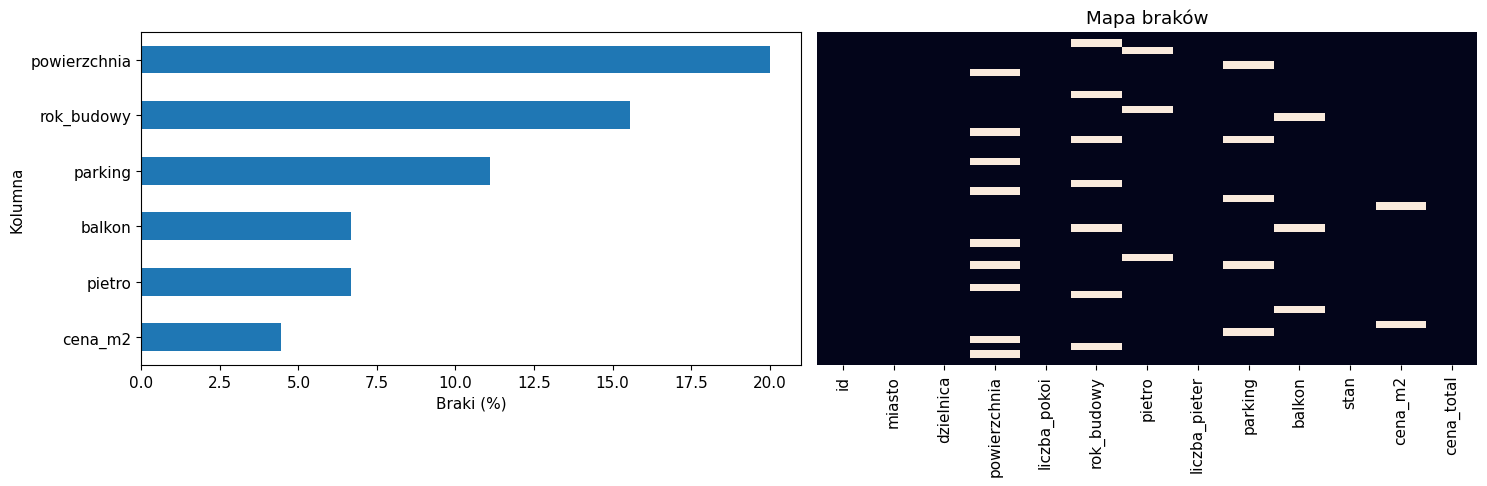

Korelacja wskaźników braków:
              powierzchnia  rok_budowy  pietro  parking  balkon  cena_m2
powierzchnia          1.00       -0.21   -0.13    -0.00   -0.13    -0.11
rok_budowy           -0.21        1.00   -0.11     0.04    0.13    -0.09
pietro               -0.13       -0.11    1.00    -0.09   -0.07    -0.06
parking              -0.00        0.04   -0.09     1.00   -0.09    -0.08
balkon               -0.13        0.13   -0.07    -0.09    1.00    -0.06
cena_m2              -0.11       -0.09   -0.06    -0.08   -0.06     1.00


In [12]:
odsetki = 100 * mieszkania.isna().mean()
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
odsetki[odsetki > 0].sort_values().plot.barh(ax=ax[0])
ax[0].set(xlabel="Braki (%)", ylabel="Kolumna")
sns.heatmap(mieszkania.isna(), cbar=False, ax=ax[1], yticklabels=False)
ax[1].set(title="Mapa braków")
plt.tight_layout()
plt.show()
kol_z_brakami = mieszkania.columns[mieszkania.isna().any()]
print("Korelacja wskaźników braków:")
print(mieszkania[kol_z_brakami].isna().astype(int).corr().round(2))

*Twoja odpowiedź:* Mapa i macierz korelacji pokazują, czy brakujące wartości występują razem w tych samych ofertach. Wartości dodatnie korelacji wskaźników braków oznaczają współwystępowanie.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [13]:
pelne = mieszkania[["powierzchnia", "cena_m2", "cena_total"]].dropna()
roznice = pelne["cena_total"] - pelne["powierzchnia"] * pelne["cena_m2"]
print("Wiersze pełne:", len(pelne), "Maksymalna różnica:", roznice.abs().max())
assert np.allclose(roznice, 0), "Zależność cenowa nie jest spełniona."
przed = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
m = mieszkania["powierzchnia"].isna() & mieszkania["cena_m2"].notna()
mieszkania.loc[m, "powierzchnia"] = mieszkania.loc[m, "cena_total"] / mieszkania.loc[m, "cena_m2"]
m = mieszkania["cena_m2"].isna() & mieszkania["powierzchnia"].notna()
mieszkania.loc[m, "cena_m2"] = mieszkania.loc[m, "cena_total"] / mieszkania.loc[m, "powierzchnia"]
print("Odtworzono:", (przed - mieszkania[["powierzchnia", "cena_m2"]].isna().sum()).to_dict())

Wiersze pełne: 34 Maksymalna różnica: 0.0
Odtworzono: {'powierzchnia': 9, 'cena_m2': 2}


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [14]:
kolumny_do_uzupelnienia = ["rok_budowy", "pietro", "parking", "balkon"]
for kol in kolumny_do_uzupelnienia:
    mieszkania[f"{kol}_brak"] = mieszkania[kol].isna().astype(int)
print("Mediany lat budowy według miasta:", mieszkania.groupby("miasto")["rok_budowy"].median(), sep="\n")
print("Mediany lat budowy według stanu:", mieszkania.groupby("stan")["rok_budowy"].median(), sep="\n")
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(
    mieszkania.groupby("miasto")["rok_budowy"].transform("median"))
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mieszkania["rok_budowy"].median())
mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)
for kol in ["parking", "balkon"]:
    print(kol, "udział Tak wśród znanych:", mieszkania[kol].eq("Tak").sum() / mieszkania[kol].notna().sum())
    print(kol, "udział Tak po imputacji dominantą:",
          mieszkania[kol].fillna(mieszkania[kol].mode()[0]).eq("Tak").mean())
    mieszkania[kol] = mieszkania[kol].fillna("nieznane")
print("Braki po czyszczeniu:", mieszkania.isna().sum().sum())

Mediany lat budowy według miasta:
miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64
Mediany lat budowy według stanu:
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64
parking udział Tak wśród znanych: 0.85
parking udział Tak po imputacji dominantą: 0.8666666666666667
balkon udział Tak wśród znanych: 0.8333333333333334
balkon udział Tak po imputacji dominantą: 0.8444444444444444
Braki po czyszczeniu: 0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

Przed:
       powierzchnia   rok_budowy       cena_m2
count     36.000000    38.000000     43.000000
mean      64.638889  2010.289474  10223.255814
std       13.684512     7.828941   1611.689030
min       42.000000  1995.000000   8200.000000
25%       54.750000  2004.250000   9000.000000
50%       63.000000  2011.500000   9800.000000
75%       72.750000  2016.750000  11100.000000
max       95.000000  2022.000000  15000.000000
Po:
       powierzchnia   rok_budowy       cena_m2
count     45.000000    45.000000     45.000000
mean      64.933333  2010.511111  10244.336043
std       12.755391     7.405073   1623.857997
min       42.000000  1995.000000   8200.000000
25%       56.000000  2005.000000   9000.000000
50%       62.000000  2013.000000   9800.000000
75%       72.000000  2016.000000  11200.000000
max       95.000000  2022.000000  15000.000000


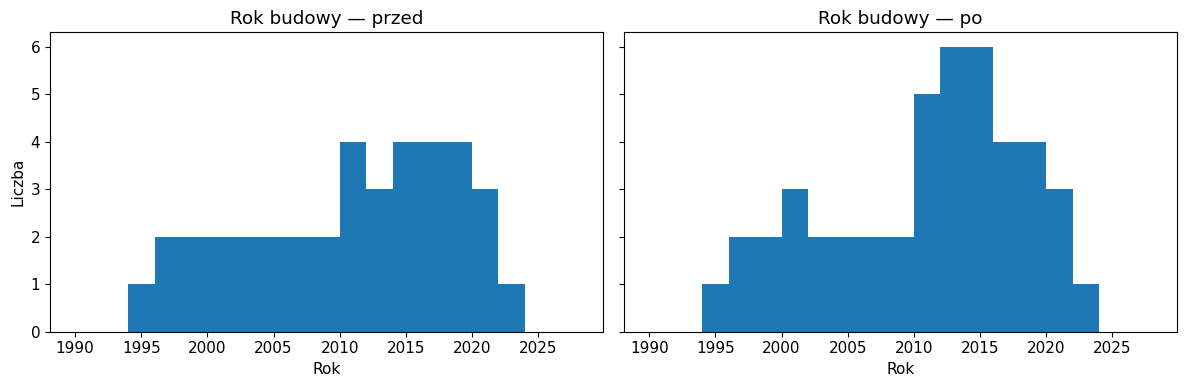

In [15]:
przed = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kol_stat = ["powierzchnia", "rok_budowy", "cena_m2"]
print("Przed:", przed[kol_stat].describe(), sep="\n")
print("Po:", mieszkania[kol_stat].describe(), sep="\n")
bins = np.arange(1990, 2030, 2)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
ax[0].hist(przed["rok_budowy"].dropna(), bins=bins)
ax[0].set(title="Rok budowy — przed", xlabel="Rok", ylabel="Liczba")
ax[1].hist(mieszkania["rok_budowy"], bins=bins)
ax[1].set(title="Rok budowy — po", xlabel="Rok")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Tak uzupełnienie zmieniło w istotny sposób histogramy. Po uzupełnieniu widać w latach 2010-2020 istotne zwiększenie budynków powstałych w tych latach w porównaniu z histogramem przed uzupełnieniem.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` |puste pole (NaN): 4; brak: 2; 0: 3 |9 |Odtworzyć z cena_total / cena_m2 | Powierzchnia 0 m² jest niepoprawna, a pozostałe dane pozwalają obliczyć brakujące wartości.|
| `cena_m2` | -1: 1; -999: 1|2 |	Odtworzyć z cena_total / powierzchnia |cena_total / powierzchnia	Ujemna cena za m² to kod braku, a nie rzeczywista cena. |
| `rok_budowy` |puste pole (NaN): 4; brak: 3 |7 |	Uzupełnić medianą w obrębie miasta, awaryjnie medianą globalną; dodać flagę braku |Mediana jest odporna na wartości skrajne, a lokalizacja może mieć znaczenie dla wieku budynku. |
| `pietro` |-999: 2; brak: 1 | 3| 	Uzupełnić liczba_pieter // 2; dodać flagę braku|Jest to przybliżenie położenia lokalu w budynku, a nie pewna informacja. Piętro 0 pozostaje poprawnym parterem. |
| `parking` |?: 5 | 5 |	Zastąpić kategorią nieznane; dodać flagę braku |Brak informacji nie oznacza automatycznie ani Tak, ani Nie. |
| `balkon` | ?: 3| 3 | 	Zastąpić kategorią nieznane; dodać flagę braku|Nie należy przypisywać cechy bez podstaw w danych.|
| `stan` | Brak brakujących oznaczeń; nietypowy zapis 很好: 1| 0 |	Zamienić 很好 na Bardzo dobry |To ujednolicenie kategorii (chiński zapis „bardzo dobry”), nie imputacja braku. |

Analiza do zadania 14 wykonana przez bielika.ai:
Niekompletne dane:

Wiele wpisów ma brakujące informacje, np. N/A dla powierzchni (pozycja 6), brak dla roku budowy (pozycje 2, 9, 15, 18, 24, 34, 42) lub -999 dla piętra (pozycje 11, 31, 36).
Niektóre wpisy mają zerową powierzchnię (pozycja 14) lub brak danych o liczbie pokoi (pozycja 14).
Niespójności w formacie:

Wartości takie jak NA (pozycje 2, 3, 11) lub ? (pozycje 5, 14, 22, 30) są niejednoznaczne i nieczytelne.
Wartość N/A dla powierzchni (pozycja 6) jest nieprawidłowa w kontekście listy.
Błędy w danych liczbowych:

Wartość 0 dla powierzchni (pozycja 14) jest niemożliwa.
Wartość -999 dla piętra (pozycje 11, 31, 36) jest nieprawidłowa.
Wartość brak dla roku budowy (pozycje 2, 9, 15, 18, 24, 34, 42) jest niejednoznaczna.
Niespójności w opisach:

Wartość Tak lub Nie dla parkingu lub balkonu jest poprawna, ale brakuje spójności w zapisie (np. Tak vs Yes).
Wartości takie jak Dobry, Bardzo dobry, Do remontu są poprawne, ale brakuje spójności w zapisie (np. Dobry vs 很好 w pozycji 2).
Nieprawidłowe wartości cenowe:

Wartość -1 dla ceny m² w pozycji 24 jest niemożliwa.
Wartość -999 dla ceny m² w pozycji 40 jest niemożliwa.
Niespójności w nazwach miast i dzielnic:

Wartości takie jak Warszawa,Mokotów (pozycja 1) mają spację, podczas gdy inne wpisy mają przecinek (np. Kraków,Krowodrza).
Brak spójności w formatowaniu:

Niektóre wpisy mają spójny format (np. 1,Warszawa,Mokotów,65,3,2015,4,10,Tak,Tak,Dobry,12500,812500), podczas gdy inne mają różne separatory (spacje, przecinki).

Jak widać bielik dobrze poradził sobie z danymi i znalazł wszystkie błedy/brakujące dane.

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [ ]:
# TODO

*Twoja odpowiedź:* …